In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import random
import io
import os

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Inferencia_estadistica/")

iris= sns.load_dataset("iris")
iris.head(2)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa


C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_2144\2827947004.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(iris["sepal_length"], hist= True, kde= True, bins= 36)


<Axes: xlabel='sepal_length', ylabel='Density'>

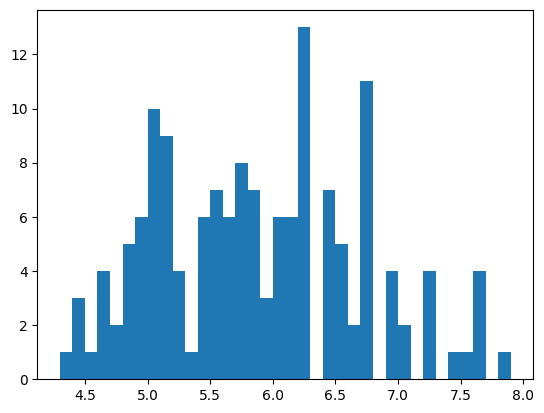

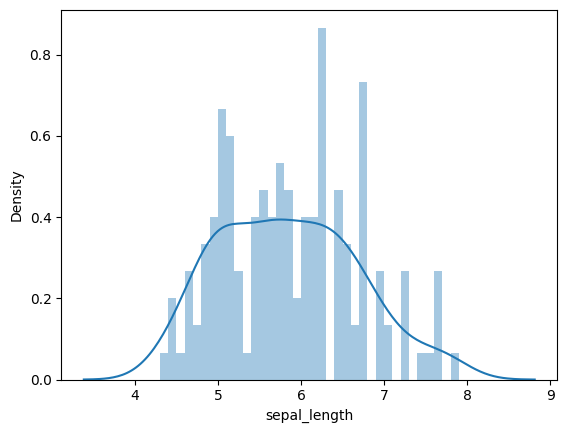

In [2]:
#VARIANZA Y DESVIACION ESTANDAR

plt.hist(iris["sepal_length"], bins= 36)

plt.figure()
sns.distplot(iris["sepal_length"], hist= True, kde= True, bins= 36)

In [4]:
#Calculo de la varianza

print("Poblacion")
print(iris["sepal_length"].var())
print(iris["sepal_length"].std())
print(iris["sepal_length"].mean())

muestra= iris.sample(frac= 0.5) #Crear una muestra

print("Muestra")
print(muestra["sepal_length"].var())
print(muestra["sepal_length"].std())
print(muestra["sepal_length"].mean())

Poblacion
0.6856935123042507
0.828066127977863
5.843333333333334
Muestra
0.772583783783784
0.8789674531993684
5.772


(array([2.93201634, 2.92062172]), array([6.92208653, 6.93348116]))

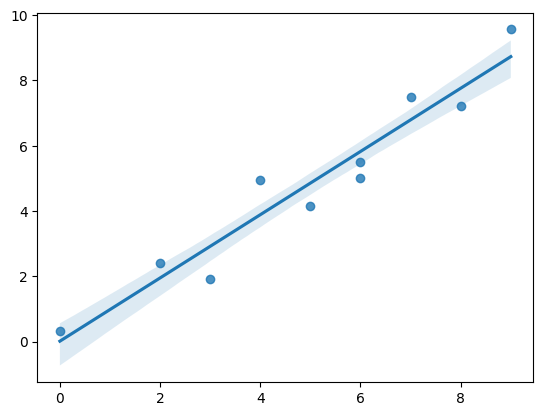

In [16]:
#INTERVALOS DE CONFIANZA
np.random.seed(20)
var1= np.random.randint(0,10,10) #Dias de vaciones
var2= var1 + np.random.normal(0,1,10) #Dinero gastado

#Visualizacion de datos con un 80% de invertalos de confianza
grafico= sns.regplot(x=var1, y=var2, ci=80)

tuple= list(zip(var1,var2))

tabla= pd.DataFrame(tuple,
columns= ["Dias_vacaciones","Dinero_gastado"])

st.t.interval(confidence=0.95, df=len(tabla)-1, loc=np.mean(tabla), scale=st.sem(tabla))  
#st.t.interval: Calcular un intervalo de confianza utilizando la distribución t de Student
#confidence=0.95: Calcular intervalo con el 95% de confianza. 
#df=len(tabla)-1: Establecer los grados de libertad 
#loc=np.mean(tabla): Calcular la media muestral de la tabla
#scale=st.sem(tabla): Especificar el error estándar de la media muestral

In [13]:
#PRUEBA DE HIPOTESIS 
from scipy.stats import f_oneway
from scipy.stats import ttest_ind

iris= sns.load_dataset("iris")
iris.head(3)

#Prueba t-Student
se_length = iris["sepal_length"].std()/np.sqrt(10) #Calcular la desviacion estandar para una muestra de tamaño 10 
se_width = iris["sepal_width"].std()/np.sqrt(10)

sed= np.sqrt((se_length**2)+(se_width**2))#Calcular el error estandar

t_stat= (iris["sepal_length"].mean()-iris["sepal_width"].mean())/sed #Hacer la prueba t-Student
t_stat

p_value= ttest_ind(iris["sepal_length"],iris["sepal_width"]) #Calcular el valor p
p_value #Rechazamos la hipotesis nula, por lo tanto, elegimos la hipotesis alternativa y encontramos que hay diferencias sigfinicativas

TtestResult(statistic=36.463283934449116, pvalue=7.027919392009369e-112, df=298.0)

In [22]:
#Correlacion y coeficiente de pearson
np.corrcoef(iris["sepal_length"],iris["sepal_width"])[0,1]
st.pearsonr(iris["sepal_length"],iris["sepal_width"]) #Rechazamos la hipotesis nula. No hay una correlacion.

PearsonRResult(statistic=-0.11756978413300206, pvalue=0.15189826071144746)

In [23]:
#Analisis ANOVA
f_oneway(iris["sepal_length"],iris["sepal_width"]) #Rechazamos la hipotesis nula. Si hay diferencias significativas.

F_onewayResult(statistic=1329.571075284254, pvalue=7.027919392009457e-112)

In [33]:
#BOOSTRAPING PARA RE-MUESTREOS

data= np.random.normal(loc= 34, size=10000) #Generar 10000 datos con media de 34
data.mean()

promedio= []
for i in range(40): #Tomar el promedio de 40 muestras aleatorias de tamaño 5
    muestra= random.sample(data.tolist(),5)
    prom= np.mean(muestra)
    promedio.append(prom)

np.mean(promedio)

33.92947668435878

In [15]:
#VALIDACION CRUZADA PARA MODELOS DE MACHINE LEARNING

df= pd.read_csv("cancerdata.csv")
df.head(3)

numeric_df= df.select_dtypes(include= ["number"]) #Seleecionar solo las variables numericas en el df
categoric_df= df.select_dtypes(include= ["object"]) #Seleecionar solo las variables numericas en el df
#sns.heatmap(numeric_df.corr(), annot= False, cmap="coolwarm")

X= df.iloc[:,2:] #Seleccionamos las variables numericas
Y= df.iloc[:,1] #Seleccionamos la variable categorica

Y.value_counts()

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size= 0.3, random_state= 4)
modelo= DecisionTreeClassifier()
modelo.fit(X_train, Y_train)
resultado= modelo.score(X_test, Y_test)
print(resultado) #El modelo es 90% preciso

#Validacion cruzada k fold

from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

modelo= DecisionTreeClassifier()
kfold_validation= KFold(10) #Vamos a tomar 10 folds o muestras

resultados= cross_val_score(modelo, X,Y, cv= kfold_validation)
print(resultados)
resultados.mean()


0.9064327485380117
[0.89473684 0.9122807  0.89473684 0.94736842 0.9122807  0.98245614
 0.9122807  0.96491228 0.94736842 0.92857143]


0.9296992481203008